Gradient Boosting is another ensemble method where instead of creating M independent fully grown trees, we are going to have M weak predictors. This means each tree we grow is going to grow with the idea of finding the residual (error) needed from the previous tree's predictions to get to each instances true value.

So the gradient boosting works by continuosly minimizing the loss function, which is the residual of each instace such that it is (observed residual - predicted residual). So the leaves just output the amount of error your instance is from being at their true value and the error is gotten from the previous prediction function from the last tree. Therefore, gradient boosting is a sequnetial algorithm which makes it a little slower than random forests because it can not create M trees in parallel since the splits (residuals) depend on the prediction function from the last tree. 
The general formula for the prediction funciton F(X) = F0(X) + alpha*F1(x) + alpha*F2(X) + ... + alpha*FM(X)
We set the initial prediction F0(x) equal to the avg of the target column of our training data because that minimzes the residuals the most. Then from there we are trying to find the residual corrections needed to add to that initial mean in order to get to the true value.
Each region is going to be filled with residuals from the last prediction that are similar so their avg will be the output and hence used as the next adder in the prediction function once updated before the next round.

Now I'm going to first make a simple gradient boosting algorithm using regression trees and having the target value that we fit it with be the prediction function up to that point so the splits will be chosen such that they minimize the RSS in terms of the residuals.

In [2]:
from sklearn.tree import DecisionTreeRegressor
import numpy as np
from sklearn.ensemble import GradientBoostingRegressor #for after to compare
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

In [3]:
rng = np.random.default_rng(42)
X = rng.random((100, 1)) - 0.5                               # 100 instances, 1 feature, from -0.5 to 0.5
y = 3 * X[:, 0] ** 2 + 0.05 * rng.standard_normal(100)       # a U-shaped curve plus noise
alpha = 1.0

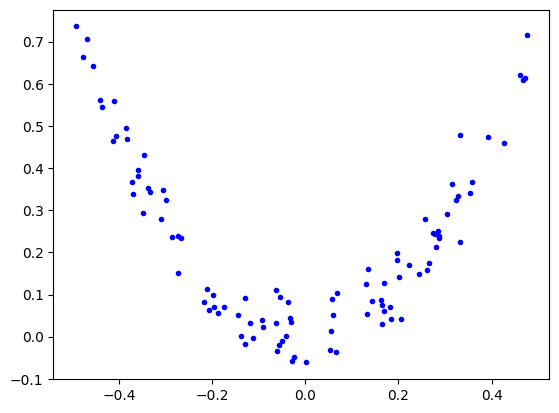

In [4]:
plt.plot(X,y,'b.')
plt.show()

In [5]:
#for the first tree we are going to use the y of the residual from the mean of the target column
target_mean = np.mean(y)
y1 = (y-target_mean) #stores the residuals for the initial mean, so our first tree's splits are built to reduce the RSS of this. We want the regions to be of around the same residual
tree_reg1 = DecisionTreeRegressor(max_depth=2, random_state=42)
tree_reg1.fit(X,y1) #fits on current prediction function

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

In [6]:
pred_2 = target_mean + tree_reg1.predict(X) #this is new prediction function. It adds the residual region to the mean. now we are going to go again
y2 = y-pred_2 #holds the residual needed to get to true value after this prediction
tree_reg2 = DecisionTreeRegressor(max_depth=2, random_state=42)
tree_reg2.fit(X,y2)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

In [15]:
pred_3 = target_mean + tree_reg1.predict(X) + tree_reg2.predict(X)
y3 = y - pred_3 #the residuals from the new prediction function. this will be the splitter for our 3rd tree
tree_reg3 =DecisionTreeRegressor(max_depth=2, random_state=42)
tree_reg3.fit(X,y3)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

In [16]:
final_pred = lambda x: target_mean + tree_reg1.predict(x) + tree_reg2.predict(x) + tree_reg3.predict(x)


In [18]:
np.mean((y-final_pred(X))**2) #here is the final MSE, 0.0037 so it is very accurate

np.float64(0.003744842335553315)

Now lets compare my tree to the real gradient boost model using the same settings


In [25]:
GBreg = GradientBoostingRegressor(learning_rate=1.0,max_depth=2, random_state=42,n_estimators=3)
GBreg.fit(X,y)

,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",1.0
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",3
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`

In [29]:
preds = GBreg.predict(X)
np.mean((y-preds)**2) #got the same as our custom gradient boosted alg using the same settings (limited to only 3 trees to correct the residuals it took in)

np.float64(0.003744842335553315)

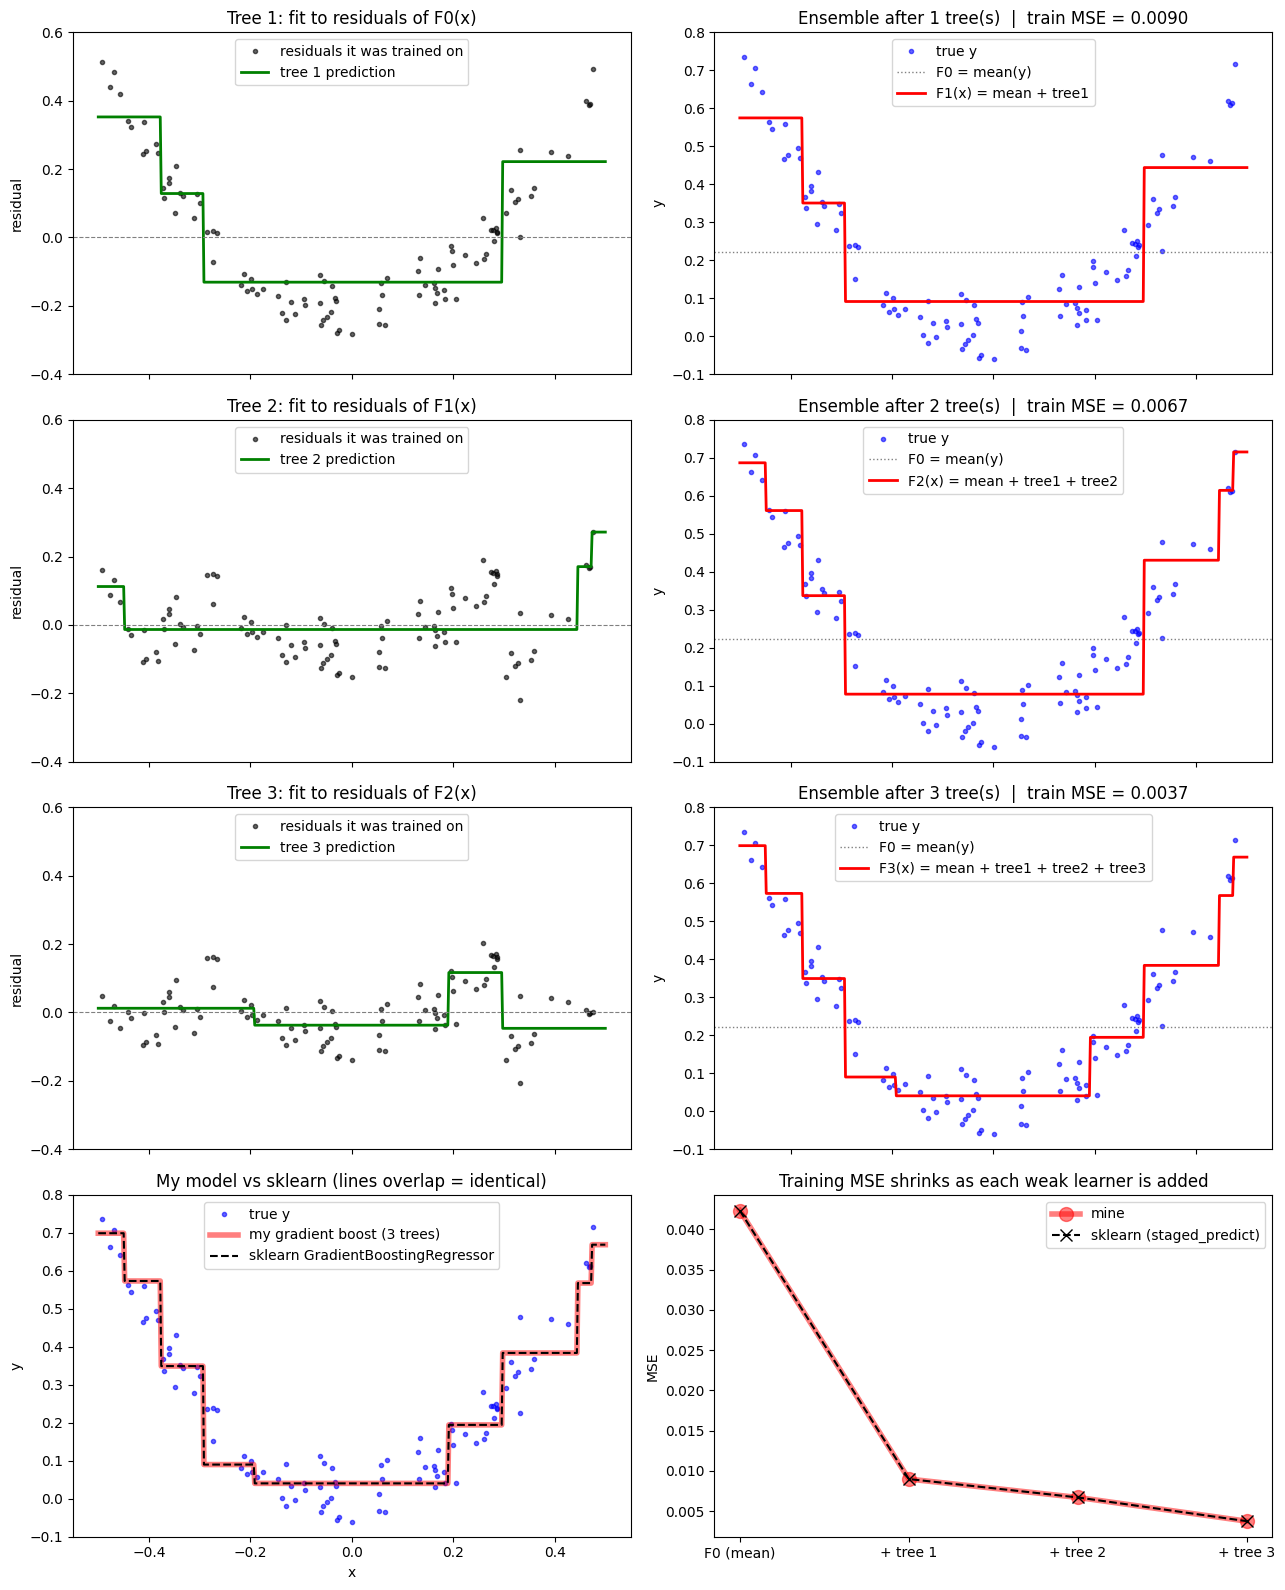

In [30]:
x_line = np.linspace(-0.5, 0.5, 500).reshape(-1, 1)  # smooth x values so we can see each tree's step function

trees = [tree_reg1, tree_reg2, tree_reg3]
residual_targets = [y1, y2, y3]  # what each tree was trained on

fig, axes = plt.subplots(4, 2, figsize=(13, 16), sharex=True)

for i, (tree, res) in enumerate(zip(trees, residual_targets)):
    # LEFT: the residuals this tree was fit to, and the step function it learned for them
    ax = axes[i, 0]
    ax.plot(X[:, 0], res, 'k.', alpha=0.6, label='residuals it was trained on')
    ax.plot(x_line[:, 0], tree.predict(x_line), 'g-', lw=2, label=f'tree {i+1} prediction')
    ax.axhline(0, color='gray', lw=0.8, ls='--')
    ax.set_title(f'Tree {i+1}: fit to residuals of F{i}(x)')
    ax.set_ylabel('residual')
    ax.set_ylim(-0.4, 0.6)
    ax.legend(loc='upper center')

    # RIGHT: the prediction function after adding this tree (mean + tree1 + ... + tree i)
    F_line = target_mean + sum(t.predict(x_line) for t in trees[:i+1])
    F_train = target_mean + sum(t.predict(X) for t in trees[:i+1])
    mse = np.mean((y - F_train) ** 2)
    ax = axes[i, 1]
    ax.plot(X[:, 0], y, 'b.', alpha=0.6, label='true y')
    ax.axhline(target_mean, color='gray', lw=1, ls=':', label='F0 = mean(y)')
    terms = ' + '.join(['mean'] + [f'tree{j+1}' for j in range(i+1)])
    ax.plot(x_line[:, 0], F_line, 'r-', lw=2, label=f'F{i+1}(x) = {terms}')
    ax.set_title(f'Ensemble after {i+1} tree(s)  |  train MSE = {mse:.4f}')
    ax.set_ylabel('y')
    ax.set_ylim(-0.1, 0.8)
    ax.legend(loc='upper center')

# BOTTOM LEFT: my 3-tree model vs sklearn's GradientBoostingRegressor
ax = axes[3, 0]
ax.plot(X[:, 0], y, 'b.', alpha=0.6, label='true y')
ax.plot(x_line[:, 0], final_pred(x_line), 'r-', lw=4, alpha=0.5, label='my gradient boost (3 trees)')
ax.plot(x_line[:, 0], GBreg.predict(x_line), 'k--', lw=1.5, label='sklearn GradientBoostingRegressor')
ax.set_title('My model vs sklearn (lines overlap = identical)')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_ylim(-0.1, 0.8)
ax.legend(loc='upper center')

# BOTTOM RIGHT: training MSE after each round, mine vs sklearn's staged predictions
my_mse = [np.mean((y - target_mean) ** 2)]
for i in range(3):
    my_mse.append(np.mean((y - (target_mean + sum(t.predict(X) for t in trees[:i+1]))) ** 2))
sk_mse = [np.mean((y - target_mean) ** 2)] + [np.mean((y - p) ** 2) for p in GBreg.staged_predict(X)]
ax = axes[3, 1]
ax.remove()  # x isn't shared with the other plots here, so make a fresh axis
ax = fig.add_subplot(4, 2, 8)
ax.plot(range(4), my_mse, 'ro-', lw=4, alpha=0.5, markersize=10, label='mine')
ax.plot(range(4), sk_mse, 'kx--', markersize=8, label='sklearn (staged_predict)')
ax.set_xticks(range(4))
ax.set_xticklabels(['F0 (mean)', '+ tree 1', '+ tree 2', '+ tree 3'])
ax.set_title('Training MSE shrinks as each weak learner is added')
ax.set_ylabel('MSE')
ax.legend()

plt.tight_layout()
plt.show()